In [2]:
from sklearn.metrics import mean_absolute_percentage_error


In [11]:
!pip install shap pandas scikit-learn matplotlib


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import shap

In [13]:
df = pd.read_csv("merged_development_data_full.csv")
df.head()

,Country,Year,Access to electricity (% of population),R&D spending (% of GDP),GDP per capita,Education spending (% of GDP),Health spending (% of GDP),Unemployment rate (% of labor force),Life expectancy at birth,Population growth (annual %),...,GNI per capita,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Afghanistan,2000,4.4,NaN,174.930991,NaN,NaN,7.935,55.005,1.212176,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,2001,9.3,NaN,138.706822,NaN,NaN,7.953,55.511,0.762005,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,2002,14.1,NaN,178.954088,NaN,9.443391,7.930,56.225,5.252030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,2003,19.0,NaN,198.871116,NaN,8.941258,7.880,57.171,6.145194,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,2004,23.8,NaN,221.763654,NaN,9.808474,7.899,57.810,3.575835,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
print(df.columns.tolist())


['Country', 'Year', 'Access to electricity (% of population)', 'R&D spending (% of GDP)', 'GDP per capita', 'Education spending (% of GDP)', 'Health spending (% of GDP)', 'Unemployment rate (% of labor force)', 'Life expectancy at birth', 'Population growth (annual %)', 'HDI', 'Life expectancy', 'Expected years of schooling', 'Mean years of schooling', 'GNI per capita', 'region', 'happiness_score', 'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'year']


In [16]:
# Define input (X) and output (y) columns
input_cols = [
    'Access to electricity (% of population)',
    'R&D spending (% of GDP)',
    'Education spending (% of GDP)',
    'Health spending (% of GDP)',
    'Unemployment rate (% of labor force)',
    'Life expectancy at birth',
    'Population growth (annual %)',
    'Life expectancy',
    'Expected years of schooling',
    'Mean years of schooling',
    'GNI per capita',
    'social_support',
    'healthy_life_expectancy',
    'freedom_to_make_life_choices',
    'generosity',
    'perceptions_of_corruption'
]

output_cols = [
    'gdp_per_capita',
    'HDI',
    'happiness_score'
]

# Split into X and y
X = df[input_cols]
y = df[output_cols]


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [19]:
# Create the model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Impute missing values in y_train with the mean of each column
from sklearn.impute import SimpleImputer

# Create an imputer that replaces NaN with the mean
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

# Fit the imputer on the training data and transform both training and testing data
y_train_imputed = imputer.fit_transform(y_train)
y_test_imputed = imputer.transform(y_test)

# Train the model
rf_model.fit(X_train, y_train_imputed)

RandomForestRegressor(random_state=42)

In [20]:
y_pred = rf_model.predict(X_test)


In [22]:
import pandas as pd

for i, col in enumerate(y.columns):
    # Get only rows where y_test[col] is not NaN
    valid_mask = ~y_test[col].isna()

    if valid_mask.sum() == 0:
        print(f"--- {col} ---")
        print("⚠️ Skipped: No valid (non-NaN) entries in y_test.")
        continue

    actual = y_test[col][valid_mask]
    predicted = y_pred[:, i][valid_mask.to_numpy()]  # use boolean mask to filter predictions

    print(f"--- {col} ---")
    print("R² Score:", r2_score(actual, predicted))
    print("MAE:", mean_absolute_error(actual, predicted))
    print("MAPE:", mean_absolute_percentage_error(actual, predicted))
    print()


--- gdp_per_capita ---
R² Score: 0.8234036401208151
MAE: 0.14421426330513898
MAPE: 17859883815434.86

--- HDI ---
R² Score: 0.7947700524781234
MAE: 0.04850143052549343
MAPE: 0.07456166631801549

--- happiness_score ---
R² Score: 0.8611706505888977
MAE: 0.299638588530327
MAPE: 0.06312317304593512



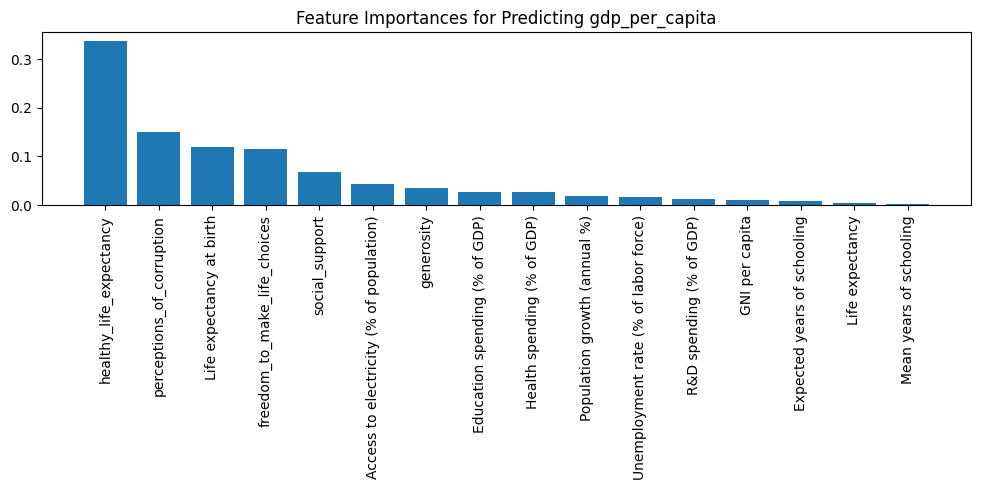

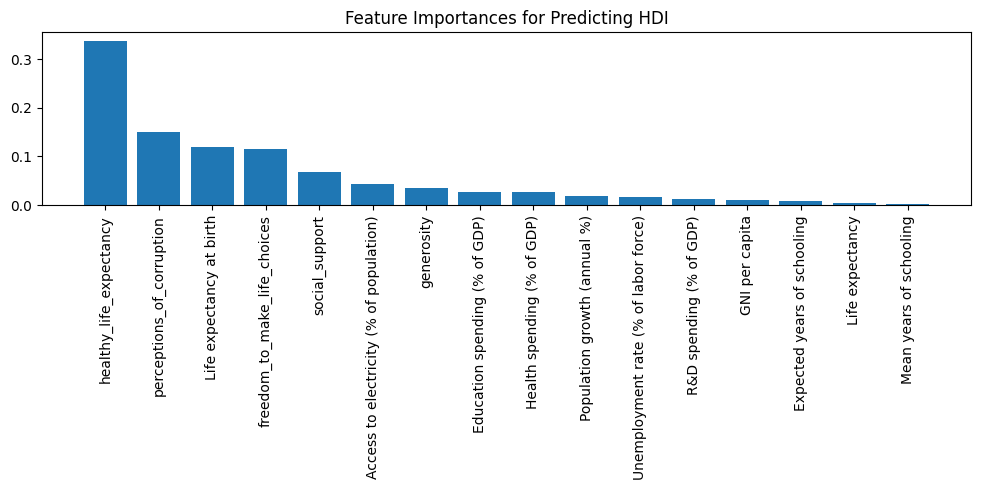

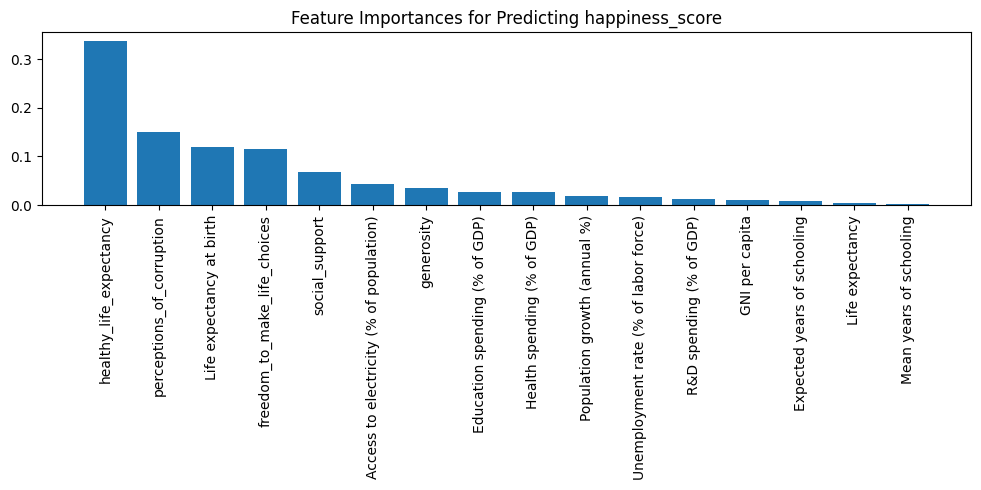

In [24]:
import matplotlib.pyplot as plt
import numpy as np

for i, col in enumerate(output_cols):
    importances = rf_model.feature_importances_
    indices = np.argsort(importances)[::-1]
    plt.figure(figsize=(10, 5))
    plt.title(f"Feature Importances for Predicting {col}")
    plt.bar(range(len(input_cols)), importances[indices])
    plt.xticks(range(len(input_cols)), [input_cols[j] for j in indices], rotation=90)
    plt.tight_layout()
    plt.show()

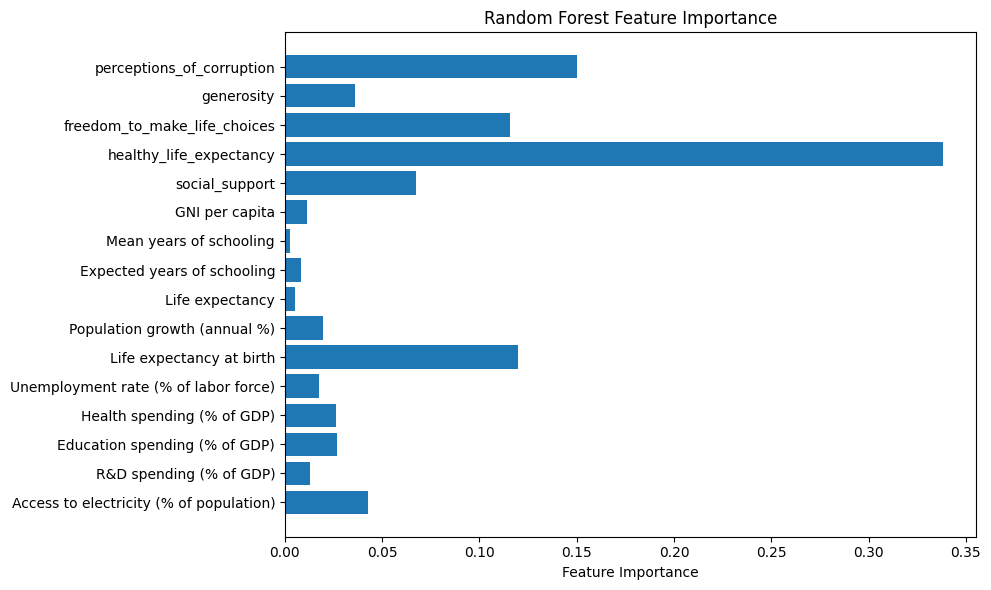

In [25]:
import matplotlib.pyplot as plt

importances = rf_model.feature_importances_
feature_names = X.columns

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importances)
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()
